# 02 · Event labels and cold fronts: from a first draft to a shared definition

PRs #9 and #11 · sessions **A5** and **A6** in the AI log · shared data preparation for both pairs

For the AI-aided vs. human-only comparison both pairs must analyse **the same events**. This notebook
replays how the definitions were drafted with the AI and where human checks changed them.

**How to read this notebook.** Each step starts with an *AI collaboration* box: what Sandro asked
(reconstructed from the PR description, not a verbatim quote), what the AI assistant proposed, how
it was checked by a human, and what was decided. The code below the box re-computes the evidence from
the repo, so the decision can be checked rather than believed. The full log is in
[`ai-interactions/phase1-ai-aided-pair.md`](../ai-interactions/phase1-ai-aided-pair.md).

In [1]:
from pathlib import Path
import json, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def repo_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "data_acquisition").is_dir() and (p / "README.md").exists():
            return p
    raise FileNotFoundError("run this notebook inside the ai-vis-lab-2026 repo")

ROOT = repo_root()
DATA = ROOT / "data" / "austria_15km"
SITE = ROOT / "phase1-model-behavior" / "pair-1" / "dashboard" / "site" / "data"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.width", 140)
print("repo:", ROOT.name, "| 15 km data present:", (DATA / "grid_long.parquet").exists())

repo: ai-vis-lab-2026 | 15 km data present: True


In [2]:
import argparse
sys.path.insert(0, str(ROOT / "data_acquisition" / "events"))
import build_events as be

id_col, wide, xy = be.load(DATA / "grid_long.parquet")
T, P = wide["T2M"], wide["P0"]
dt24, dt1 = be.deltas(T)
print(f"{T.shape[1]} points x {T.shape[0]} hours, {T.index[0]:%Y-%m-%d} to {T.index[-1]:%Y-%m-%d} (UTC)")

378 points x 8760 hours, 2025-10-01 to 2026-09-30 (UTC)


## Step 1 · Cold-wave days: which definition reproduces the agreed numbers?

> **AI collaboration · A5 · cold-wave days**
>
> | | |
> |---|---|
> | **Prompt** *(reconstructed)* | Write <code>build_events.py</code> with the thresholds from <code>model-selection.md</code>: cold drop = at least 8 K colder than the same hour yesterday; cold-wave day = at least 25 % of Austria in a cold drop. |
> | **AI proposal** | A cold-wave day when ≥ 25 % of the locations have a cold drop at <b>any hour</b> of the day. |
> | **Human check** | Compared with the agreed count in <code>model-selection.md</code> (29 days on the 5 km grid). The AI version gave 42. |
> | **Decision** | Modified: ≥ 25 % <b>at the same hour</b>. Only that reproduces the 29 days, and it means one large-scale event, not scattered drops. |

In [3]:
cold = dt24 <= -8
same_hour = be.cold_wave_days(cold, dt24.notna())                       # final definition
any_hour = cold.groupby(cold.index.floor("D")).any().mean(axis=1)        # first AI draft
print("cold-wave days, 15 km grid")
print(f"  any hour of the day (AI draft): {(any_hour >= 0.25).sum()}")
print(f"  same hour (final):              {same_hour.cold_wave.sum()}")
print("  (5 km grid, from PR #9: 42 vs. 29 agreed)")

cold-wave days, 15 km grid
  any hour of the day (AI draft): 42
  same hour (final):              27
  (5 km grid, from PR #9: 42 vs. 29 agreed)


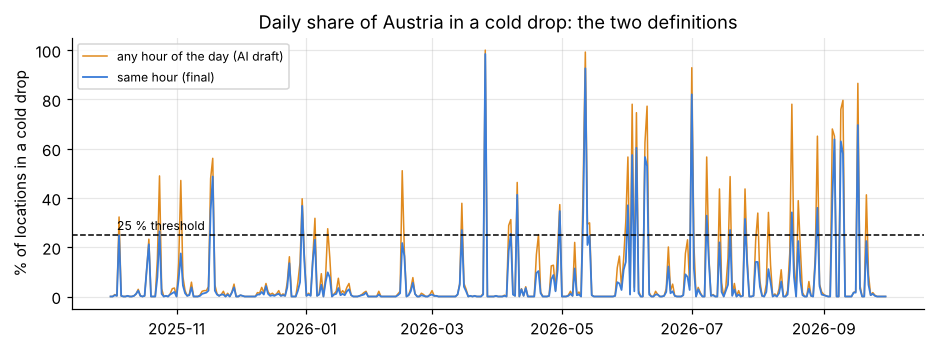

15 days only under the AI draft, e.g. ['2025-10-05', '2025-11-03', '2026-01-05', '2026-01-11', '2026-02-15']


In [4]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(any_hour.index, any_hour.values * 100, color="#e08a1e", lw=1, label="any hour of the day (AI draft)")
ax.plot(pd.to_datetime(same_hour.index), same_hour.share.values * 100, color="#3b7dd8", lw=1.2, label="same hour (final)")
ax.axhline(25, color="black", ls="--", lw=1); ax.text(any_hour.index[3], 27, "25 % threshold", fontsize=8)
ax.set_ylabel("% of locations in a cold drop"); ax.legend(fontsize=8, loc="upper left")
ax.set_title("Daily share of Austria in a cold drop: the two definitions")
plt.show()
extra = sorted(set(any_hour[any_hour >= 0.25].index.date) - set(same_hour.index[same_hour.cold_wave]))
print(len(extra), "days only under the AI draft, e.g.", [str(d) for d in extra[:5]])

The orange line is above the blue one on many days: drops at different hours of the day add up, so the
*any hour* version counts days where many local drops happened, not one cold wave. The check was
simple — reproduce a number the team already agreed — and it is what caught it.

## Step 2 · Filling gaps: a subtle pandas trap

> **AI collaboration · A5 · gap filling**
>
> | | |
> |---|---|
> | **Prompt** *(reconstructed)* | Fill short gaps in T2M before taking differences. |
> | **AI proposal** | <code>T2M.interpolate(limit=3)</code> (also used in the smoke test). |
> | **Human check** | Read the pandas docs: <code>limit=3</code> fills the <i>first 3 hours of a long gap</i> too, so a 10-hour outage becomes 3 invented values and 7 NaN. |
> | **Decision** | Modified: <code>fill_short_gaps</code> fills a gap only if the whole gap is at most 3 h, with a test for it. |

In [5]:
s = pd.Series([1.0, np.nan, np.nan, 4.0, 5.0] + [np.nan] * 8 + [14.0, 15.0], name="T2M")
demo = pd.DataFrame({"raw": s, "interpolate(limit=3)": s.interpolate(limit=3),
                     "fill_short_gaps(3)": be.fill_short_gaps(s.to_frame(), 3)["T2M"]})
print("2-hour gap: filled by both. 8-hour gap: pandas invents 3 values, fill_short_gaps leaves it empty.")
print("Missing T2M values in the 15 km dataset:", int(T.isna().sum().sum()), "of", T.size)
demo.T.round(1)

2-hour gap: filled by both. 8-hour gap: pandas invents 3 values, fill_short_gaps leaves it empty.
Missing T2M values in the 15 km dataset: 378 of 3311280


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
raw,1.0,NaN,NaN,4.0,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.0,15.0
interpolate(limit=3),1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,NaN,NaN,NaN,NaN,NaN,14.0,15.0
fill_short_gaps(3),1.0,2.0,3.0,4.0,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.0,15.0


## Step 3 · A cold drop is not a cold front

> **AI collaboration · A6 · cold-front label**
>
> | | |
> |---|---|
> | **Prompt** *(reconstructed)* | Our cold drop says that it is colder, not <i>when</i> a front arrives. Define a cold front from the literature: the surface signature at each point, and a line moving across Austria. |
> | **AI proposal** | Passage at a point: 3 h cooling ≤ −3 K and 6 h pressure rise ≥ +2 hPa, both as anomalies for that point, month and hour. Front: ≥ 50 % of points within 24 h, passage times fit a moving plane (R² ≥ 0.3, 1–30 m/s, coming from W or N). References, a sensitivity table, and <code>fronts.csv</code> with the reason for every verdict. |
> | **Human check** | Checked the thresholds on calm days and on the big events, checked the references, and ran an independent check with wind and rain (not part of the definition). |
> | **Decision** | Accepted after verification; winter fronts are a known gap (cold-air pools hide the surface signature). |

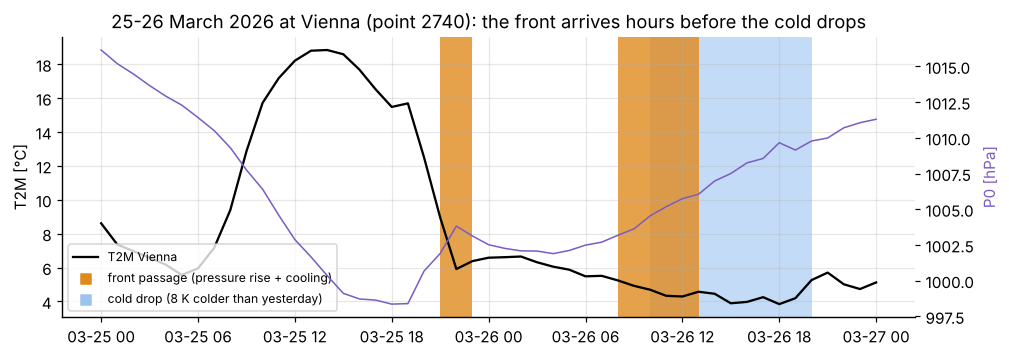

In [6]:
vienna = 313   # column index of the point nearest Vienna (see forecast_runs.json -> places)
pid = T.columns[vienna]
win = slice("2026-03-25 00:00", "2026-03-27 00:00")
passage = be.passages(T, P)
fig, ax = plt.subplots(figsize=(10, 3.3))
ax.plot(T.loc[win].index, T.loc[win, pid], color="black", lw=1.5, label="T2M Vienna")
ax2 = ax.twinx(); ax2.plot(P.loc[win].index, P.loc[win, pid] / 100, color="#7a5cc4", lw=1, label="P0 (hPa)")
ax2.set_ylabel("P0 [hPa]", color="#7a5cc4"); ax2.grid(False)
for t in cold.loc[win].index[cold.loc[win, pid]]:
    ax.axvspan(t, t + pd.Timedelta("1h"), color="#9cc3f0", alpha=0.6, lw=0)
for t in passage.loc[win].index[passage.loc[win, pid]]:
    ax.axvspan(t, t + pd.Timedelta("1h"), color="#e08a1e", alpha=0.8, lw=0)
ax.scatter([], [], marker="s", color="#e08a1e", label="front passage (pressure rise + cooling)")
ax.scatter([], [], marker="s", color="#9cc3f0", label="cold drop (8 K colder than yesterday)")
ax.legend(fontsize=8, loc="lower left"); ax.set_ylabel("T2M [°C]")
ax.set_title(f"25-26 March 2026 at Vienna (point {pid}): the front arrives hours before the cold drops")
plt.show()

The orange passage hours (cooling **with** a pressure jump) come first; the blue cold-drop hours come
the next afternoon, when it is simply colder than the day before. For questions about *when* the model
fails (Q5), only the passage time is useful.

## Step 4 · Rebuilding the front list and seeing why candidates fail

In [7]:
args = argparse.Namespace(cold_k=8.0, storm_k=3.0, storm_rr=2.0, cold_share=0.25, front_k=3.0, front_hpa=2.0,
                          front_share=0.5, front_r2=0.3, max_gap=3, episode_gap=6)
events, days, fl = be.build(id_col, wide, xy, args)
released = pd.read_csv(DATA / "fronts.csv", parse_dates=["peak_time"])
same = (fl.peak_time.values == released.peak_time.values).all() and (fl.cold_front.values == released.cold_front.values).all()
print(f"rebuilt: {fl.cold_front.sum()} cold fronts of {len(fl)} candidates; identical to the release file: {same}")

rebuilt: 16 cold fronts of 39 candidates; identical to the release file: True


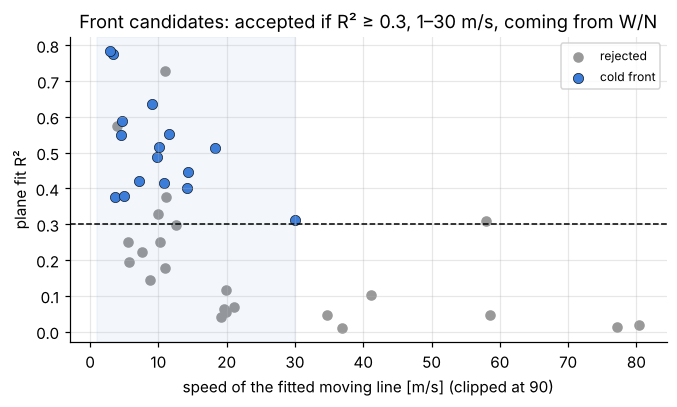

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ok = fl.cold_front
ax.scatter(fl.speed_ms[~ok].clip(upper=90), fl.r2[~ok], color="0.6", label="rejected", s=35)
ax.scatter(fl.speed_ms[ok], fl.r2[ok], color="#3b7dd8", label="cold front", s=45, edgecolor="black", lw=0.4)
ax.axhline(0.3, color="black", ls="--", lw=1); ax.axvspan(1, 30, color="#3b7dd8", alpha=0.06)
ax.set_xlabel("speed of the fitted moving line [m/s] (clipped at 90)"); ax.set_ylabel("plane fit R²")
ax.set_title("Front candidates: accepted if R² ≥ 0.3, 1–30 m/s, coming from W/N"); ax.legend(fontsize=8)
plt.show()

## Step 5 · Independent check with variables that are not in the definition

If the label really finds fronts, other front signs should show up even though they were not used: the
wind should turn to a northerly direction and it should often rain. PR #11 reported *wind turns towards
north in 38 % of passages (17 % of all hours), rain in 77 % (14 %)*. The cell below runs a simple version
of that check (northerly = wind from 300° to 60° within 3 h after the passage onset; rain = any rain
within ±3 h). The exact numbers depend on these choices, so they will not match the PR to the decimal.

In [9]:
g = pd.read_parquet(DATA / "grid_long.parquet", columns=["point_id", "time", "RR", "wind_dir"])
rr = g.pivot(index="time", columns="point_id", values="RR").reindex(T.index)
wd = g.pivot(index="time", columns="point_id", values="wind_dir").reindex(T.index)
north = ((wd >= 300) | (wd <= 60)).astype(float)
cf = events[events.kind == "cold_front"].sort_values("time").groupby("episode").first()   # onset per episode
ti = T.index.get_indexer(cf.time); ci = T.columns.get_indexer(cf.point_id)
ok_i = (ti >= 3) & (ti < len(T) - 4)
rain_win = np.stack([rr.to_numpy()[ti[ok_i] + d, ci[ok_i]] for d in range(-3, 4)]).max(axis=0) > 0
north_win = np.stack([north.to_numpy()[ti[ok_i] + d, ci[ok_i]] for d in range(1, 4)]).max(axis=0) > 0
base_rain = (rr.rolling(7, center=True).max() > 0).to_numpy().mean()
base_north = (north.rolling(3).max().shift(-3) > 0).to_numpy().mean()
check = pd.DataFrame({"at front passages %": [north_win.mean() * 100, rain_win.mean() * 100],
                      "all hours %": [base_north * 100, base_rain * 100]},
                     index=["northerly wind within 3 h after", "rain within ±3 h"]).round(0)
print(f"{ok_i.sum()} passage onsets")
check

5672 passage onsets


,at front passages %,all hours %
northerly wind within 3 h after,54.0,43.0
rain within ±3 h,95.0,29.0


With this simple version, rain is a strong confirmation (rain around almost every passage, against
about a third of all hours). The wind signal is weaker: a northerly direction becomes more common, but
"from 300° to 60°" is a broad sector and valley winds in the Alps blur it. PR #11 used a stricter
definition and found a clearer contrast. Either way, both variables point the same way although neither
is part of the label.

## Step 6 · How sensitive is the front count to the thresholds?

In [10]:
rows = []
for k in [2.0, 3.0, 4.0]:
    pas = be.passages(T, P, temp_k=k)
    for r2 in [0.2, 0.3, 0.4]:
        f, _ = be.fronts(pas, xy, min_r2=r2)
        rows.append({"cooling K": k, "min R²": r2, "candidates": len(f), "cold fronts": int(f.cold_front.sum())})
sens = pd.DataFrame(rows).pivot(index="cooling K", columns="min R²", values="cold fronts")
print("number of cold fronts (default: 3 K, R² 0.3)")
sens

number of cold fronts (default: 3 K, R² 0.3)


min R²,0.2,0.3,0.4
cooling K,,,
2.0,37,31,26
3.0,20,16,13
4.0,14,13,10


### What these steps show about the collaboration

- The AI drafted fast and with references, but **the definition was settled by reproducing an agreed
  number** (29 days) and by **testing with variables that were not used** (wind, rain).
- The `interpolate(limit=3)` issue is a typical AI pattern: common, plausible code with a side effect that
  only matters in edge cases. It barely changes this dataset (one missing hour), but a shared definition
  has to be right.
- Keeping rejected candidates in `fronts.csv` with a reason made the rule checkable. The same table drives
  the Q3 page of the dashboard.